# COMP 577 — Homework 1: Panorama Stitching

Working notebook, built step by step together.

Using your own reference photo sequence (`my_images/image_1.jpg` ... `image_4.jpg`,
already 480px tall like the handout suggests) instead of a synthetic stand-in.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import distance_transform_edt

%matplotlib inline
print("cv2", cv2.__version__)


cv2 4.13.0


## Load the sequence

Sanity-check: read the images, confirm ordering and that neighboring images overlap.

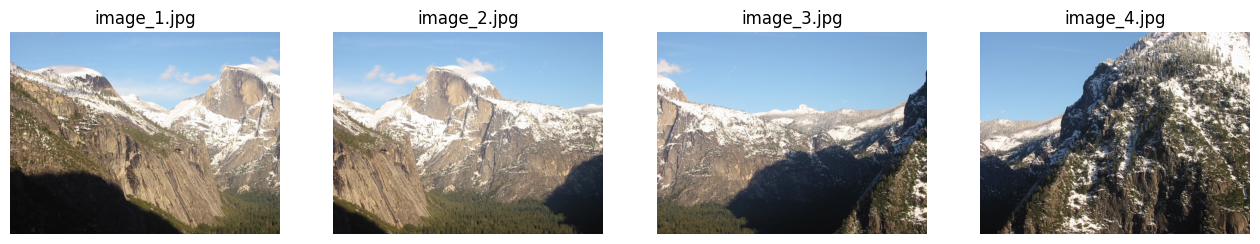

In [2]:
image_paths = [f"my_images/image_{i}.jpg" for i in range(1, 5)]
images_bgr = [cv2.imread(p) for p in image_paths]

fig, axes = plt.subplots(1, len(images_bgr), figsize=(16, 4))
for ax, img, p in zip(axes, images_bgr, image_paths):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(p.split('/')[-1])
    ax.axis('off')
plt.show()


## Step 1: Feature detection and description (5 pts)

For each image: convert to grayscale, optionally resize, then run a feature
detector+descriptor. The assignment calls out Harris / Blob / SIFT as the
detectors we covered — SIFT is the natural pick here since it's the one that's
*both* scale- and rotation-invariant, which matters because our camera views
won't be perfectly aligned or at identical distances.

**Your turn:** write a function

```python
def detect_features(img_bgr):
    # convert to grayscale
    # (optional) resize
    # run cv2.SIFT_create() + detectAndCompute
    # return: keypoints, descriptors, the (possibly resized) grayscale image used
```

Then run it on all 5 images and visualize one with `cv2.drawKeypoints` to sanity
check (should look like Figure 1 in the handout — lots of circles at corners/blobs).

In [3]:
def detect_features(img_bgr):
    """
    Run SIFT detection + description on one image.
    Returns: keypoints, descriptors, and the grayscale image SIFT actually saw.
    """
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    sift = cv2.SIFT_create()
    keypoints, descriptors = sift.detectAndCompute(gray, None)
    return keypoints, descriptors, gray

# Run it on every image in the sequence
features = [detect_features(img) for img in images_bgr]

for path, (kp, des, gray) in zip(image_paths, features):
    print(f"{path}: {len(kp)} keypoints, descriptor shape {des.shape}")


my_images/image_1.jpg: 2504 keypoints, descriptor shape (2504, 128)
my_images/image_2.jpg: 2343 keypoints, descriptor shape (2343, 128)
my_images/image_3.jpg: 1957 keypoints, descriptor shape (1957, 128)
my_images/image_4.jpg: 3676 keypoints, descriptor shape (3676, 128)


**What just happened:**
- `cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)` — SIFT operates on a single intensity
  channel, not color, so we collapse the 3 color channels down to one grayscale image
  (this is why your Harris/blob derivations were always in terms of a single `I(x,y)` too).
- `cv2.SIFT_create()` — builds a SIFT detector+descriptor object with default parameters
  (number of octaves, contrast threshold for rejecting weak keypoints, etc.).
- `sift.detectAndCompute(gray, None)` — does two things in one call: **detect** finds
  keypoint locations (the scale-space extrema you derived — blob-like maxima/minima of
  the DoG, each with a location, characteristic scale, and orientation), and **compute**
  builds the 128-dim descriptor vector around each one. The `None` argument means "no
  mask" — i.e. search the whole image, not just some sub-region.
- Each keypoint has `.pt` (x, y location), `.size` (its characteristic scale), and
  `.angle` (its dominant orientation) — exactly the 3 quantities scale/rotation invariance
  needs.

Now let's visualize them, the same way Figure 1 in the handout does.

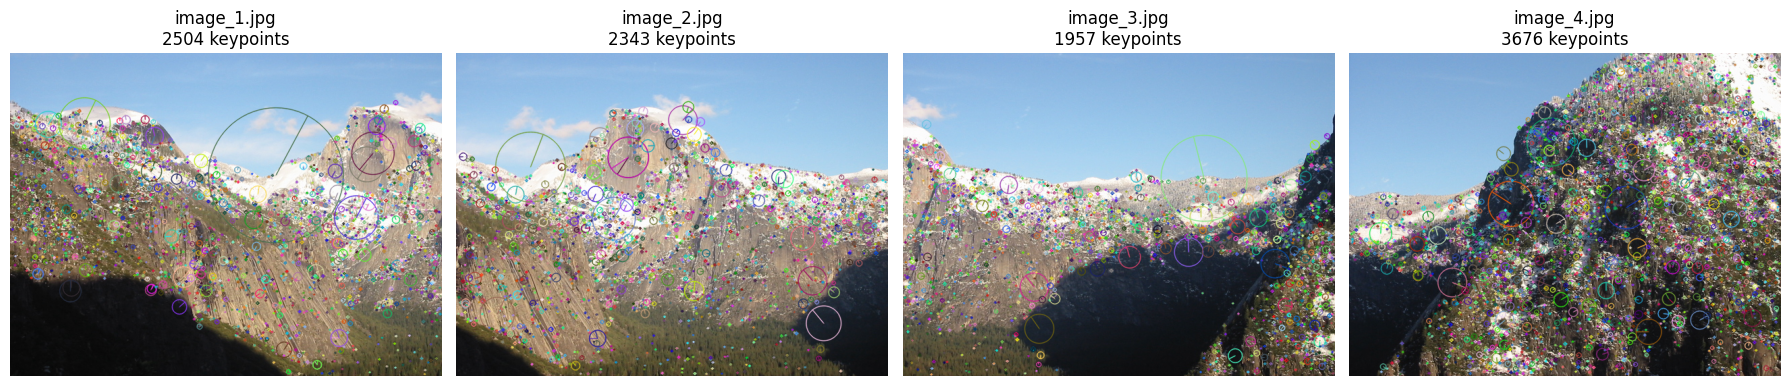

In [4]:
fig, axes = plt.subplots(1, len(images_bgr), figsize=(18, 5))
for ax, img, (kp, des, gray), path in zip(axes, images_bgr, features, image_paths):
    # drawKeypoints with DRAW_RICH_KEYPOINTS shows each keypoint as a circle sized to
    # its scale, with a line showing its orientation -- not just a dot.
    vis = cv2.drawKeypoints(img, kp, None,
                             flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{path.split('/')[-1]}\n{len(kp)} keypoints")
    ax.axis('off')
plt.tight_layout()
plt.savefig('step1_keypoints.png', dpi=110)
plt.show()
